In [1]:
from math import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def get_feature_matrix(x, order):
    X = np.ones((len(x), order + 1))
    for i in range(1, order + 1):
        X[:, i] = x ** i
    return X

def get_trigonometric_feature_matrix(x, order):
    X = np.ones((len(x), 2 * order + 1))
    for i in range(1, order + 1):
        X[:, 2 * i - 1] = np.cos(i * x)
        X[:, 2 * i] = np.sin(i * x)
    return X

In [3]:
order = 2

### 1. Получить данные

In [4]:
x = np.linspace(0.0, 2.0*pi, 10)
y = 1 + np.sin(x) + 2 * np.cos(x) + 0.1 * np.random.randn(10)

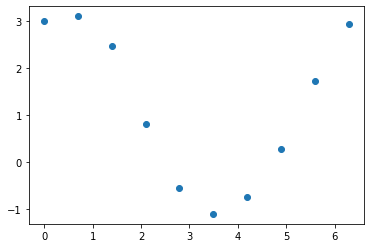

In [5]:
fig, ax = plt.subplots(1, 1)
ax.scatter(x, y)
#plt.show(scatter_train)

### 2. Определиться с моделью, найти матрицу признаков

In [6]:
X = get_trigonometric_feature_matrix(x, order)

### 3. Находим оптимальную модель

In [7]:
#theta = np.linalg.inv(X.T @ X) @ X.T @ y
theta = np.linalg.solve(X.T @ X, X.T @ y)

### 4. Оценим модель на обучающейся выборке

In [8]:
y_pred = X @ theta
mse_train = sum((y - y_pred) ** 2) / len(y)
print(f'MSE for TRAIN: {mse_train}')

MSE for TRAIN: 0.003524207536766354


### 5. Оценим модель на тестовой выборке

In [10]:
x_test = np.linspace(0.0, 2.0*pi, 1000)
y_test = 1 + np.sin(x) + 2 * np.cos(x) + 0.01 * np.random.randn(1000)
X_test = get_trigonometric_feature_matrix(x_test, order)
y_test_pred = X_test @ theta

In [11]:
mse_test = sum((y_test - y_test_pred) ** 2) / len(y_test)
print(f'MSE for TEST: {mse_test}')

MSE for TEST: 0.006481790405133345


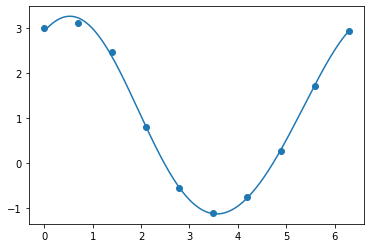

In [12]:
#line_test = plt.plot(x_test, y_test_pred, '-')
ax.plot(x_test, y_test_pred, '-')
fig